<a href="https://colab.research.google.com/github/vigneshwaranmanikandan/data-science/blob/main/Confidence_interval_L3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import stats, norm, binom

In [15]:
df = pd.read_csv(r"/content/insurance.csv")

In [16]:
#Select 50 random customers and calculate the mean charges.
sample_data = df.sample(n=50, random_state=42)
sample_mean = sample_data['charges'].mean()
print("Sample Mean:", sample_mean)

Sample Mean: 13498.0618316


In [17]:
#Population mean
population_mean = df['charges'].mean()
print("Population Mean:", population_mean)
print("Sample Mean:", sample_mean)

Population Mean: 13270.422265141257
Sample Mean: 13498.0618316


In [18]:
#Calculate a 95% confidence interval for their mean charges.
from scipy.stats import t
n = len(sample_data)
sample_std = sample_data['charges'].std()
confidence=0.95
alpha=1-confidence
critical_value = t.ppf(1-alpha/2, df=n-1)

margin_error = critical_value * (sample_std/np.sqrt(n))
lower = sample_mean- margin_error
upper = sample_mean + margin_error
print("Sample Mean: ", sample_mean)
print("Lower Bound: ", lower)
print("Upper Bound: ", upper)
print("Confidence Interval: ", (lower, upper))

Sample Mean:  13498.0618316
Lower Bound:  9722.273317527928
Upper Bound:  17273.850345672072
Confidence Interval:  (np.float64(9722.273317527928), np.float64(17273.850345672072))


In [19]:
#Repeat the experiment with sample sizes of 30, 50, 100 and 500.
sample_30 = df.sample(n=30, random_state=42)
sample_30_mean = sample_30['charges'].mean()
print("Size 30 Sample Mean:", sample_30_mean)

sample_100 = df.sample(n=100, random_state=42)
sample_100_mean = sample_100['charges'].mean()
print("Size 100 Sample Mean:", sample_100_mean)

sample_500 = df.sample(n=500, random_state=42)
sample_500_mean = sample_500['charges'].mean()
print("Size 500 Sample Mean:", sample_500_mean)

Size 30 Sample Mean: 15123.986305
Size 100 Sample Mean: 13807.148351900003
Size 500 Sample Mean: 13179.462509238001


In [20]:
#Size = 30
from scipy.stats import t
n = len(sample_30)
sample_30_std = sample_30['charges'].std()
confidence=0.95
alpha=1-confidence
critical_value = t.ppf(1-alpha/2, df=n-1)

margin_error = critical_value * (sample_30_std/np.sqrt(n))
lower_30 = sample_30_mean- margin_error
upper_30 = sample_30_mean + margin_error
print("Sample Mean: ", sample_30_mean)
print("lower_30 Bound: ", lower_30)
print("upper_30 Bound: ", upper_30)
print("Confidence Interval: ", (lower_30, upper_30))
print()
#Size = 100
from scipy.stats import t
n = len(sample_100)
sample_100_std = sample_100['charges'].std()
confidence=0.95
alpha=1-confidence
critical_value = t.ppf(1-alpha/2, df=n-1)

margin_error = critical_value * (sample_100_std/np.sqrt(n))
lower_100 = sample_100_mean- margin_error
upper_100 = sample_100_mean + margin_error
print("Sample Mean: ", sample_100_mean)
print("lower_100 Bound: ", lower_100)
print("upper_100 Bound: ", upper_100)
print("Confidence Interval: ", (lower_100, upper_100))
print()
#Size = 500
from scipy.stats import t
n = len(sample_500)
sample_500_std = sample_500['charges'].std()
confidence=0.95
alpha=1-confidence
critical_value = t.ppf(1-alpha/2, df=n-1)

margin_error = critical_value * (sample_500_std/np.sqrt(n))
lower_500 = sample_500_mean- margin_error
upper_500 = sample_500_mean + margin_error
print("Sample Mean: ", sample_500_mean)
print("lower_500 Bound: ", lower_500)
print("upper_500 Bound: ", upper_500)
print("Confidence Interval: ", (lower_500, upper_500))

Sample Mean:  15123.986305
lower_30 Bound:  9770.274131527563
upper_30 Bound:  20477.698478472437
Confidence Interval:  (np.float64(9770.274131527563), np.float64(20477.698478472437))

Sample Mean:  13807.148351900003
lower_100 Bound:  11320.382991854423
upper_100 Bound:  16293.913711945583
Confidence Interval:  (np.float64(11320.382991854423), np.float64(16293.913711945583))

Sample Mean:  13179.462509238001
lower_500 Bound:  12109.292133566629
upper_500 Bound:  14249.632884909373
Confidence Interval:  (np.float64(12109.292133566629), np.float64(14249.632884909373))


In [21]:
# Calculate confidence interval widths

width_30 = upper_30 - lower_30
width_50 = upper - lower
width_100 = upper_100 - lower_100
width_500 = upper_500 - lower_500

print("CI Width for Sample 30:", width_30)
print("CI Width for Sample 50:", width_50)
print("CI Width for Sample 100:", width_100)
print("CI Width for Sample 500:", width_500)

CI Width for Sample 30: 10707.424346944874
CI Width for Sample 50: 7551.577028144144
CI Width for Sample 100: 4973.530720091159
CI Width for Sample 500: 2140.3407513427446


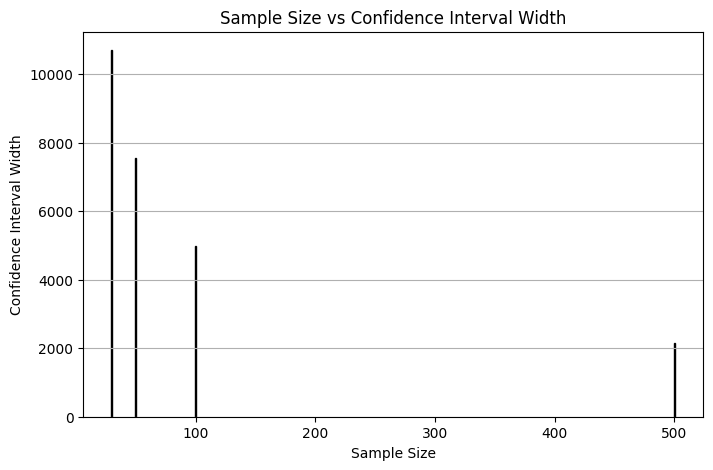

In [22]:
sample_sizes = [30, 50, 100, 500]
widths = [width_30, width_50, width_100, width_500]
plt.figure(figsize=(8, 5))
plt.bar(sample_sizes, widths, edgecolor='black')
plt.title("Sample Size vs Confidence Interval Width")
plt.xlabel("Sample Size")
plt.ylabel("Confidence Interval Width")
plt.grid(axis='y')
plt.show()

In [23]:
#Calculate a 90%, 95% and 99% confidence interval for BMI.
bmi_sample = df.sample(n=100, random_state=42)
for confidence in [0.90,0.95,0.99]:
  mean = bmi_sample['bmi'].mean()
  std = bmi_sample['bmi'].std()
  n=len(bmi_sample)
  alpha=1-confidence
  critical_value = t.ppf(1-alpha/2,df=n-1)

  margin_error = critical_value * (std/np.sqrt(n))
  lower = mean- margin_error
  upper = mean + margin_error
  print("Sample Mean: ", mean)
  print("Lower Bound: ", lower)
  print("Upper Bound: ", upper)
  print(f"Confidence Interval for : {confidence}\n", (lower, upper))
  print()

Sample Mean:  31.4516
Lower Bound:  30.475245869642215
Upper Bound:  32.42795413035778
Confidence Interval for : 0.9
 (np.float64(30.475245869642215), np.float64(32.42795413035778))

Sample Mean:  31.4516
Lower Bound:  30.284827695091597
Upper Bound:  32.618372304908405
Confidence Interval for : 0.95
 (np.float64(30.284827695091597), np.float64(32.618372304908405))

Sample Mean:  31.4516
Lower Bound:  29.90720378531916
Upper Bound:  32.99599621468084
Confidence Interval for : 0.99
 (np.float64(29.90720378531916), np.float64(32.99599621468084))



In [24]:
#Calculate a confidence interval for the population proportion of smokers.
from scipy.stats import norm
import numpy as np
smoker_count = df['smoker'].value_counts()
total = len(df)
p = smoker_count / total
print("Smoker Proportion:")
print(p)

z = norm.ppf(0.975)
n = total

denominator = 1 + (z**2 / n)
center = (p + z**2 / (2*n)) / denominator
margin = (z * np.sqrt((p * (1-p) / n) +(z**2 / (4*n**2)))/denominator)
lower = center - margin
upper = center + margin
print("\nLower Bound:")
print(lower)
print("\nUpper Bound:")
print(upper)

print("\nLower Percentage:")
print(lower * 100)
print("\nUpper Percentage:")
print(upper * 100)

Smoker Proportion:
smoker
no     0.795217
yes    0.204783
Name: count, dtype: float64

Lower Bound:
smoker
no     0.772763
yes    0.184020
Name: count, dtype: float64

Upper Bound:
smoker
no     0.815980
yes    0.227237
Name: count, dtype: float64

Lower Percentage:
smoker
no     77.276332
yes    18.402015
Name: count, dtype: float64

Upper Percentage:
smoker
no     81.597985
yes    22.723668
Name: count, dtype: float64


In [25]:
#Calculate the confidence interval for the difference in average charges between smokers and non-smokers.
from scipy.stats import t

smokers = df[df['smoker'] == 'yes']['charges']
non_smokers = df[df['smoker'] == 'no']['charges']

n1 = len(smokers)
n2 = len(non_smokers)
mean1 = smokers.mean()
mean2 = non_smokers.mean()
var1 = smokers.var()
var2 = non_smokers.var()
difference = mean1 - mean2
standard_error = np.sqrt((var1/n1) + (var2/n2))
dof = ((var1/n1 + var2/n2)**2) / (((var1/n1)**2 / (n1-1)) +((var2/n2)**2 / (n2-1)))
confidence = 0.95
alpha = 1 - confidence
critical_value = t.ppf(1 - alpha/2, df=dof)
margin_error = critical_value * standard_error
lower = difference - margin_error
upper = difference + margin_error
print("Smokers Mean Charges:", mean1)
print("Non-Smokers Mean Charges:", mean2)
print("Difference in Means:", difference)

print("Standard Error:", standard_error)
print("Degrees of Freedom:", dof)
print("Critical Value:", critical_value)
print("Margin of Error:", margin_error)

print("Lower Bound:", lower)
print("Upper Bound:", upper)

print("95% Confidence Interval:", (lower, upper))

Smokers Mean Charges: 32050.23183153284
Non-Smokers Mean Charges: 8434.268297856204
Difference in Means: 23615.963533676637
Standard Error: 721.0565602250897
Degrees of Freedom: 311.85112492054634
Critical Value: 1.9676001550136217
Margin of Error: 1418.7509996724755
Lower Bound: 22197.21253400416
Upper Bound: 25034.714533349113
95% Confidence Interval: (np.float64(22197.21253400416), np.float64(25034.714533349113))


In [26]:
#Repeat random sampling 100 times. How frequently do the calculated 95% intervals contain the full dataset mean?
population_mean = df['charges'].mean()
count = 0
rng = np.random.default_rng(42)
for i in range(100):
    sample = df['charges'].sample(n=50,random_state=rng)
    mean = sample.mean()
    lower = mean - margin_error
    upper = mean + margin_error
    if lower <= population_mean <= upper:
        count += 1

print("Total Experiments: 100")
print("Intervals containing population mean:", count)
print("Coverage Percentage:", count / 100 * 100)

Total Experiments: 100
Intervals containing population mean: 56
Coverage Percentage: 56.00000000000001
